# Board Games Data Mining
## 3. Clustering

### 3.0 Setup and Data Loading

In [1]:
import sys
print(sys.executable)

/Users/sarabiiavasco/Codice/venv/bin/python


In [2]:
%pip install scikit-learn


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path
from itertools import combinations
from math import pi
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, BisectingKMeans, DBSCAN, OPTICS, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.stats import f_oneway

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [5]:
DATA_CANDIDATES = [
    Path("data/DM1_game_dataset_prepared.csv"),
    Path("DM1_game_dataset_prepared.csv"),
    Path("Data/DM1_dataset_finale.csv"),
    Path("DM1_dataset_finale.csv"),
    Path("DM1_game_dataset_cleaned_4_ml.csv"),
    Path("DM1_game_dataset_cleaned_2_ml.csv"),
]

DATA_PATH = next((p for p in DATA_CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Prepared dataset not found. Run 01_data_understanding_preparation.ipynb first "
        "and save df_final as DM1_game_dataset_prepared.csv (preferably inside ./data/)."
    )

df = pd.read_csv(DATA_PATH)
print(f"Loaded {df.shape[0]:,} rows and {df.shape[1]} columns from {DATA_PATH}")
df.head()

Loaded 20,671 rows and 24 columns from DM1_game_dataset_prepared.csv


,YearPublished,AvgPlaytime,GameWeight,MfgAgeRec,MinPlayers,MaxPlayers,Ranking,Rating,SemanticString,NumOwned,...,IsReimplementation,Kickstarted,Cat:Thematic,Cat:Strategy,Cat:War,Cat:Family,Cat:CGS,Cat:Abstract,Cat:Party,Cat:Childrens
0,2014,3.433987,1.8333,15.0,2,4,0.499238,1,assassin s creed arena game description publis...,6.270988,...,False,False,False,False,False,False,False,False,False,False
1,2021,2.917771,1.0000,8.0,2,5,0.499238,2,bag of chips bag chip party game face crucial ...,4.290459,...,False,False,False,False,False,False,False,False,False,False
2,2020,4.510860,3.6667,12.0,1,5,0.499238,3,gùgōng deluxe big box big box contain componen...,6.727432,...,False,False,False,False,False,False,False,False,False,False
3,2004,3.044522,1.3077,10.0,2,2,0.499238,1,letterflip publisherthe reveal game secret wor...,5.043425,...,False,False,False,False,False,False,False,False,False,False
4,2019,2.917771,1.5000,8.0,2,4,0.499238,2,treasures of cibola rescue mayan treasure easy...,5.342334,...,False,False,False,False,False,False,False,False,False,False


### Feature selection and scaling

To keep the clustering methods directly comparable, we used the same six quantitative features throughout the structural clustering analysis:

- `YearPublished`
- `MfgAgeRec`
- `MaxPlayers`
- `NumOwned`
- `GameWeight`
- `AvgPlaytime`

`GameWeight` and `AvgPlaytime` are both retained because they describe different domains (complexity and duration), despite their moderate correlation. `NumDemand`, `MinPlayers`, zero-inflated count variables, and the binary category indicators are excluded from the structural clustering space for the reasons discussed in the report.

The data are scaled with **MinMaxScaler**, which was the scaling strategy retained in the final analysis. The cleaning thresholds used before clustering are also applied here: `YearPublished >= 1949` and `MaxPlayers <= 30`.

In [6]:
CLUSTER_FEATURES = [
    "YearPublished",
    "MfgAgeRec",
    "MaxPlayers",
    "NumOwned",
    "GameWeight",
    "AvgPlaytime",
]

missing = [c for c in CLUSTER_FEATURES if c not in df.columns]
if missing:
    raise ValueError(f"Missing clustering features: {missing}. The loaded file may be the raw dataset rather than the prepared one.")

X = df[CLUSTER_FEATURES].copy()
X = X[(X["YearPublished"] >= 1949) & (X["MaxPlayers"] <= 30)].dropna()

df_cluster_base = df.loc[X.index].copy()

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dataset used for structural clustering: {X.shape[0]:,} rows × {X.shape[1]} features")
display(X.describe().T)

Dataset used for structural clustering: 20,671 rows × 6 features


,count,mean,std,min,25%,50%,75%,max
YearPublished,20671.0,2006.652363,13.913514,1949.000000,2002.000000,2011.000000,2017.000000,2021.000000
MfgAgeRec,20671.0,10.332688,2.786944,1.000000,8.000000,10.000000,12.000000,25.000000
MaxPlayers,20671.0,4.948866,3.530837,1.000000,4.000000,4.000000,6.000000,30.000000
NumOwned,20671.0,6.082067,1.369172,1.098612,5.081404,5.855072,6.874198,12.022739
GameWeight,20671.0,2.032778,0.798683,1.000000,1.352900,2.000000,2.548400,5.000000
AvgPlaytime,20671.0,3.843025,0.886317,0.693147,3.258097,3.828641,4.330733,11.002117


### Shared evaluation helpers

We combined geometric quality, cluster-size balance and interpretability. The helper functions below calculate:

- silhouette score;
- coefficient of variation (**CV**) of cluster sizes;
- cluster profiles;
- one-way ANOVA effect size $\eta^2$;
- PCA, boxplot, spider/radar and pairwise projections.

In [7]:
def cluster_size_cv(labels, ignore_noise=True):
    labels = np.asarray(labels)
    if ignore_noise:
        labels = labels[labels != -1]
    if len(labels) == 0:
        return np.nan
    sizes = pd.Series(labels).value_counts().values
    return float(np.std(sizes, ddof=0) / np.mean(sizes))


def partition_summary(Xs, labels, ignore_noise=True):
    labels = np.asarray(labels)
    valid = labels != -1 if ignore_noise else np.ones(len(labels), dtype=bool)
    valid_labels = labels[valid]
    unique = np.unique(valid_labels)

    sil = np.nan
    if len(unique) >= 2 and valid.sum() > len(unique):
        sil = float(silhouette_score(Xs[valid], valid_labels))

    sizes = pd.Series(valid_labels).value_counts()
    return {
        "n_clusters": int(len(unique)),
        "silhouette": sil,
        "cv": cluster_size_cv(labels, ignore_noise=ignore_noise),
        "min_cluster_size": int(sizes.min()) if len(sizes) else 0,
        "max_cluster_size": int(sizes.max()) if len(sizes) else 0,
        "noise_ratio": float((labels == -1).mean()) if np.any(labels == -1) else 0.0,
        "dominant_share_non_noise": float(sizes.max() / sizes.sum()) if len(sizes) else np.nan,
    }


def eta_squared_anova(values, labels):
    temp = pd.DataFrame({"value": np.asarray(values), "cluster": np.asarray(labels)}).dropna()
    temp = temp[temp["cluster"] != -1]
    groups = [g["value"].values for _, g in temp.groupby("cluster")]
    if len(groups) < 2:
        return np.nan, np.nan

    f_stat, p_value = f_oneway(*groups)
    grand_mean = temp["value"].mean()
    ss_between = sum(len(g) * (np.mean(g) - grand_mean) ** 2 for g in groups)
    ss_total = ((temp["value"] - grand_mean) ** 2).sum()
    eta2 = ss_between / ss_total if ss_total > 0 else np.nan
    return float(eta2), float(p_value)


def cluster_profiles(frame, labels, features=CLUSTER_FEATURES):
    out = frame[features].copy()
    out["Cluster"] = labels
    profile = out.groupby("Cluster")[features].mean()
    profile["Count"] = out["Cluster"].value_counts().sort_index()
    return profile


def plot_pca_partition(Xs, labels, title="PCA projection"):
    coords = PCA(n_components=2).fit_transform(Xs)
    plt.figure(figsize=(9, 6))
    plt.scatter(coords[:, 0], coords[:, 1], c=labels, s=8, alpha=0.55)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(title)
    plt.show()


def plot_boxplots(frame, labels, features=CLUSTER_FEATURES, title="Cluster distributions"):
    temp = frame[features].copy()
    temp["Cluster"] = labels
    ncols = 2
    nrows = math.ceil(len(features) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.asarray(axes).reshape(-1)
    for ax, feature in zip(axes, features):
        sns.boxplot(data=temp, x="Cluster", y=feature, ax=ax)
        ax.set_title(feature)
    for ax in axes[len(features):]:
        ax.remove()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def plot_spider_profiles(frame, labels, features=CLUSTER_FEATURES, title="Cluster profiles"):
    temp = frame[features].copy()
    temp["Cluster"] = labels
    means = temp.groupby("Cluster")[features].mean()
    scaled = pd.DataFrame(
        MinMaxScaler().fit_transform(means),
        index=means.index,
        columns=means.columns,
    )

    angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
    angles += angles[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True})
    for cluster_id, row in scaled.iterrows():
        values = row.tolist() + [row.iloc[0]]
        ax.plot(angles, values, label=f"Cluster {cluster_id}")
        ax.fill(angles, values, alpha=0.10)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(features)
    ax.set_title(title)
    ax.legend(bbox_to_anchor=(1.25, 1.10))
    plt.show()


def feature_effect_sizes(frame, labels, features=CLUSTER_FEATURES):
    rows = []
    for feature in features:
        eta2, p = eta_squared_anova(frame[feature].values, labels)
        rows.append({"feature": feature, "eta2": eta2, "p_value": p})
    return pd.DataFrame(rows).sort_values("eta2", ascending=False)

## 3.1 Analysis by Centroid-Based Methods

### 3.1.1 Parameter selection and application

For K-Means, we combined the elbow method (SSE/inertia) with silhouette score and inspected `k = 3, 4, 5, 7` in detail. Bisecting K-Means was then used as a robustness check with the same scaled feature space.

,k,SSE,silhouette
0,2,1940.543793,0.266254
1,3,1510.707501,0.286467
2,4,1340.773866,0.299521
3,5,1177.139773,0.222720
4,6,1072.774234,0.218739
5,7,978.076014,0.220407
6,8,912.127297,0.218004
7,9,863.061441,0.205460


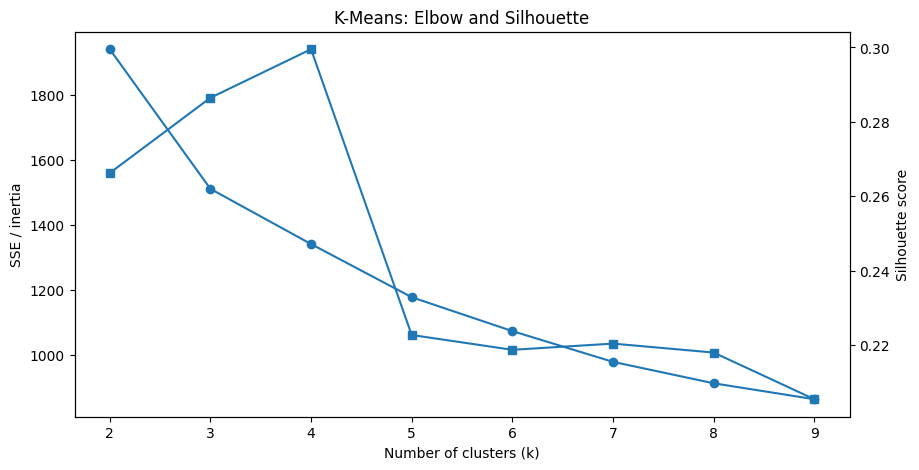

In [8]:
# K-Means model selection: elbow + silhouette
k_values = range(2, 10)
kmeans_rows = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_scaled)
    kmeans_rows.append({
        "k": k,
        "SSE": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
    })

kmeans_results = pd.DataFrame(kmeans_rows)
display(kmeans_results)

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(kmeans_results["k"], kmeans_results["SSE"], marker="o")
ax1.set_xlabel("Number of clusters (k)")
ax1.set_ylabel("SSE / inertia")

ax2 = ax1.twinx()
ax2.plot(kmeans_results["k"], kmeans_results["silhouette"], marker="s")
ax2.set_ylabel("Silhouette score")
plt.title("K-Means: Elbow and Silhouette")
plt.show()

In [9]:
# Bisecting K-Means model selection.
# n_init=10 corresponds to the final multi-initialization variant
bisect_rows = []
for k in range(2, 10):
    model = BisectingKMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10,
        bisecting_strategy="biggest_inertia",
    )
    labels = model.fit_predict(X_scaled)
    bisect_rows.append({
        "k": k,
        "SSE": model.inertia_,
        "silhouette": silhouette_score(X_scaled, labels),
    })

bisect_results = pd.DataFrame(bisect_rows)
display(bisect_results)

,k,SSE,silhouette
0,2,1940.739497,0.266549
1,3,1640.934268,0.257636
2,4,1388.628668,0.259517
3,5,1252.386716,0.271315
4,6,1148.278710,0.183488
5,7,1061.503109,0.166832
6,8,999.810841,0.164288
7,9,948.430465,0.162021


### 3.1.2 Results

We used **K-Means with k=5** as a baseline for interpretation and compared it with alternative K-Means solutions (`k=3,4,7`). The K-Means silhouettes are approximately:

- `k=3`: 0.297
- `k=4`: 0.224
- `k=5`: 0.220
- `k=7`: 0.220

For the final multi-initialization Bisecting K-Means experiment, we reported approximately **0.2540 at k=4** and **0.1905 at k=5**. We retained the **k=4 Bisecting K-Means** partition for the structural interpretation.

K-Means k=5: {'n_clusters': 5, 'silhouette': 0.22272005889311564, 'cv': 0.5950472303624512, 'min_cluster_size': 388, 'max_cluster_size': 6822, 'noise_ratio': 0.0, 'dominant_share_non_noise': 0.3300275748633351}


,YearPublished,MfgAgeRec,MaxPlayers,NumOwned,GameWeight,AvgPlaytime,Count
Cluster,,,,,,,
0,2010.391234,8.152595,5.204046,5.570585,1.305351,3.171210,6822
1,2008.260084,12.568098,3.875327,6.494071,3.266792,4.889792,3818
2,2007.180412,11.167526,24.737113,6.071680,1.473355,3.561927,388
3,2013.336561,11.331133,4.422095,6.478787,2.118374,3.840481,6816
4,1979.270251,10.052706,4.337106,5.804843,1.991985,4.095224,2827


,feature,eta2,p_value
4,GameWeight,0.728081,0.0
0,YearPublished,0.632150,0.0
2,MaxPlayers,0.619836,0.0
5,AvgPlaytime,0.460230,0.0
1,MfgAgeRec,0.366185,0.0
3,NumOwned,0.096078,0.0


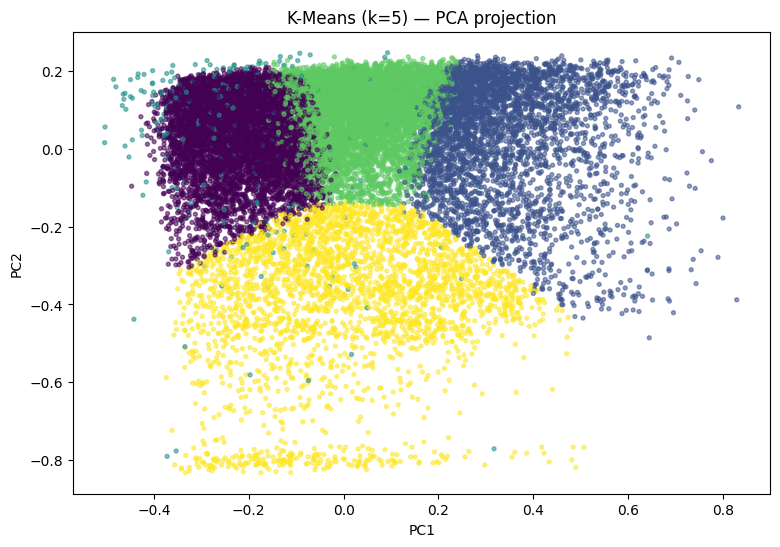

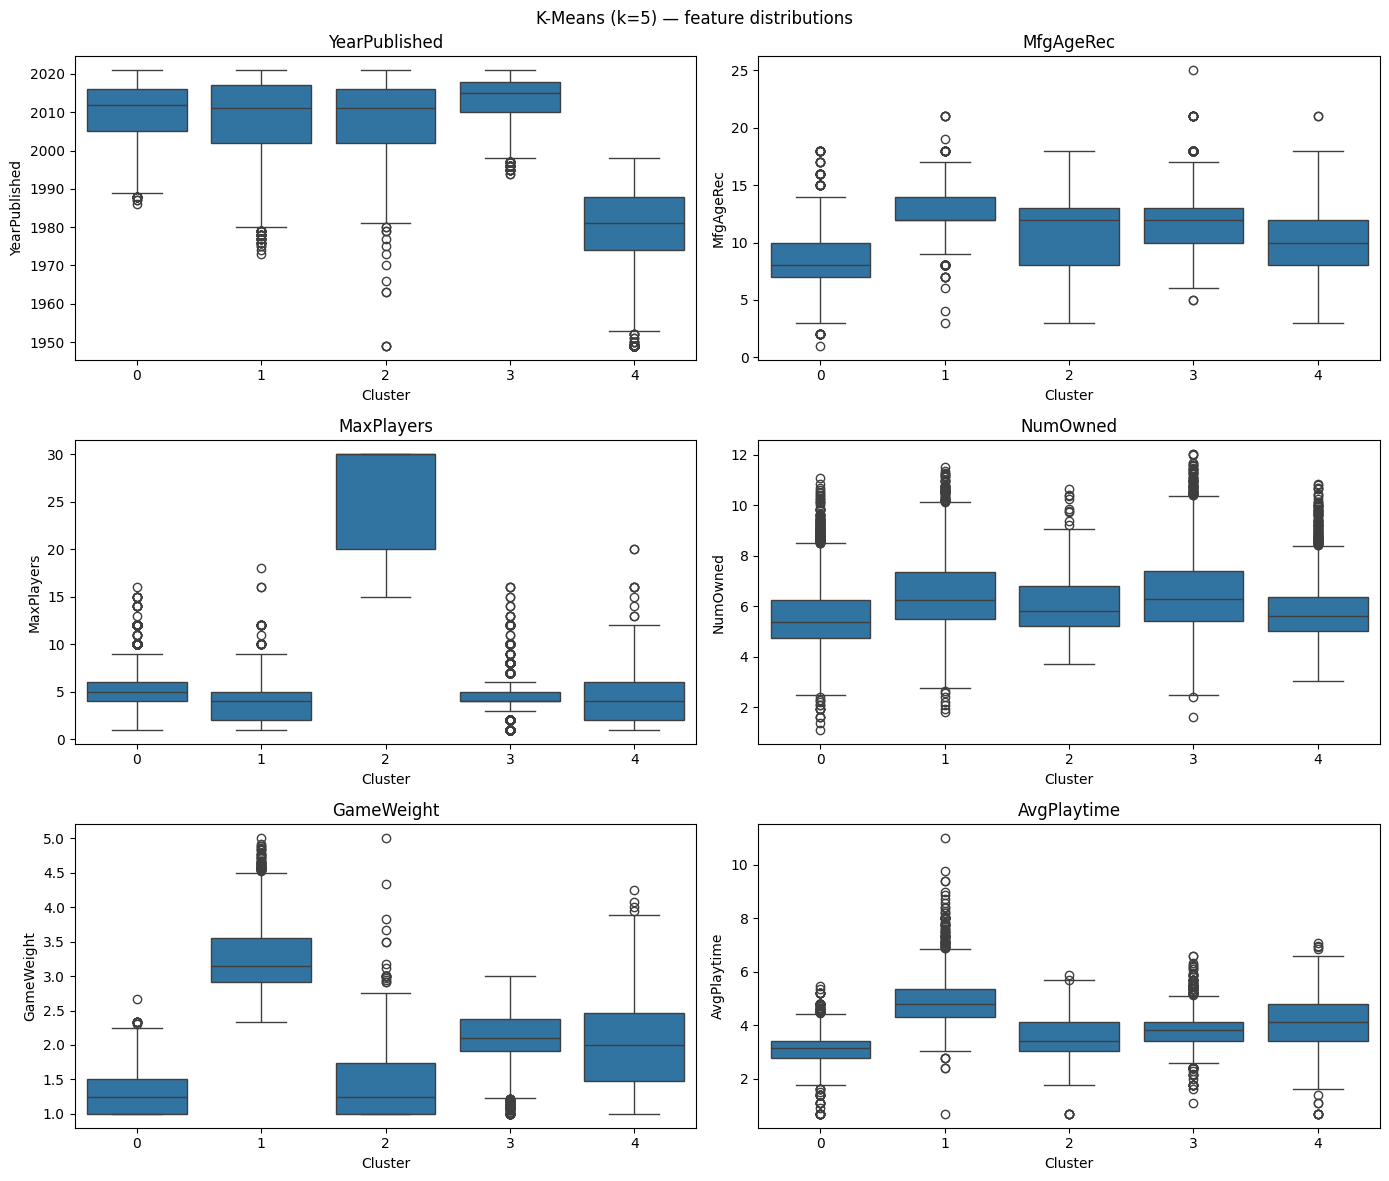

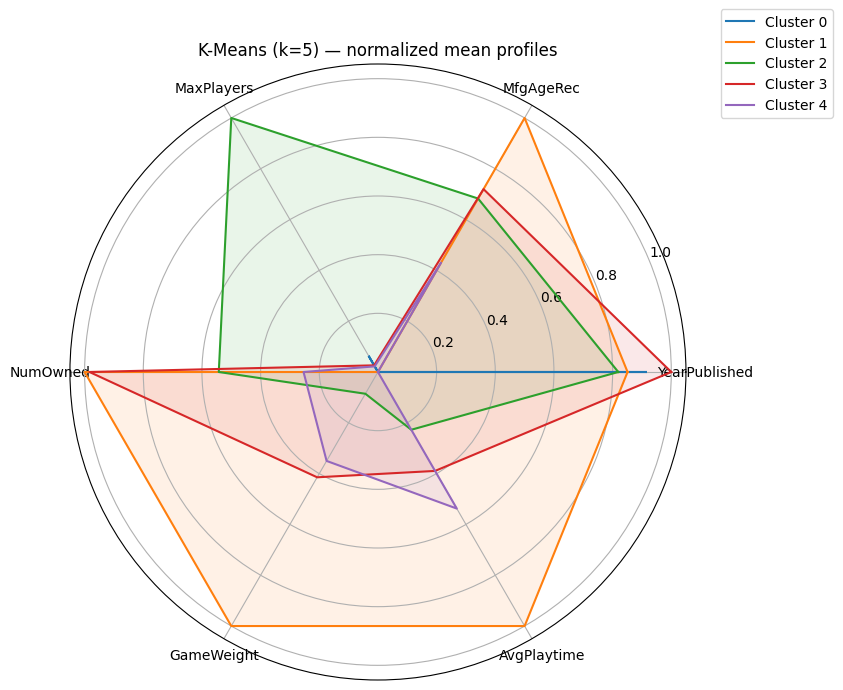

In [10]:
# Baseline K-Means solution
kmeans_k5 = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10)
labels_k5 = kmeans_k5.fit_predict(X_scaled)

print("K-Means k=5:", partition_summary(X_scaled, labels_k5))
display(cluster_profiles(X, labels_k5))
display(feature_effect_sizes(X, labels_k5))

plot_pca_partition(X_scaled, labels_k5, "K-Means (k=5) — PCA projection")
plot_boxplots(X, labels_k5, title="K-Means (k=5) — feature distributions")
plot_spider_profiles(X, labels_k5, title="K-Means (k=5) — normalized mean profiles")

Bisecting K-Means k=4: {'n_clusters': 4, 'silhouette': 0.25951723231743173, 'cv': 0.6625679308297607, 'min_cluster_size': 1995, 'max_cluster_size': 10324, 'noise_ratio': 0.0, 'dominant_share_non_noise': 0.4994436650379759}


,YearPublished,MfgAgeRec,MaxPlayers,NumOwned,GameWeight,AvgPlaytime,Count
Cluster,,,,,,,
0,1985.143791,11.843137,3.662932,5.931969,2.871476,4.918740,2142
1,2013.115942,12.236715,4.123994,6.638532,2.801572,4.408770,6210
2,1981.684712,8.597995,5.544862,5.700036,1.472435,3.565387,1995
3,2012.051724,9.209221,5.596668,5.852313,1.504609,3.333186,10324


,feature,eta2,p_value
0,YearPublished,0.698501,0.000000e+00
4,GameWeight,0.658576,0.000000e+00
5,AvgPlaytime,0.449800,0.000000e+00
1,MfgAgeRec,0.289228,0.000000e+00
3,NumOwned,0.072450,0.000000e+00
2,MaxPlayers,0.049705,4.042080e-228


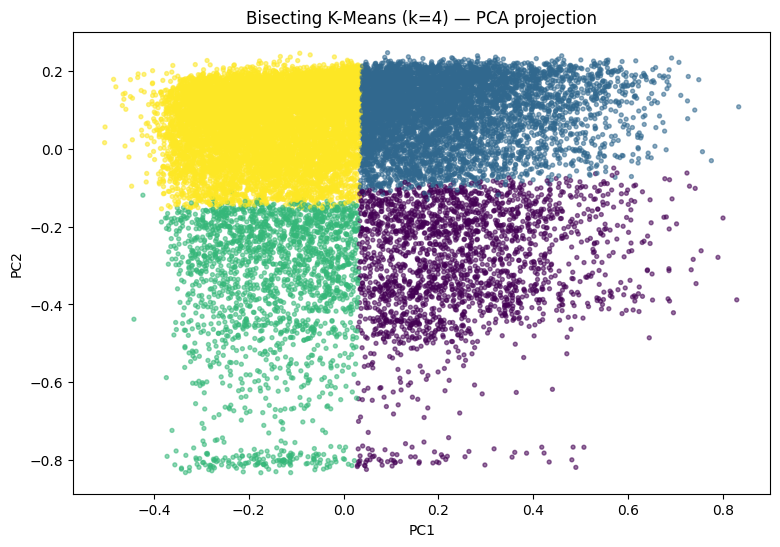

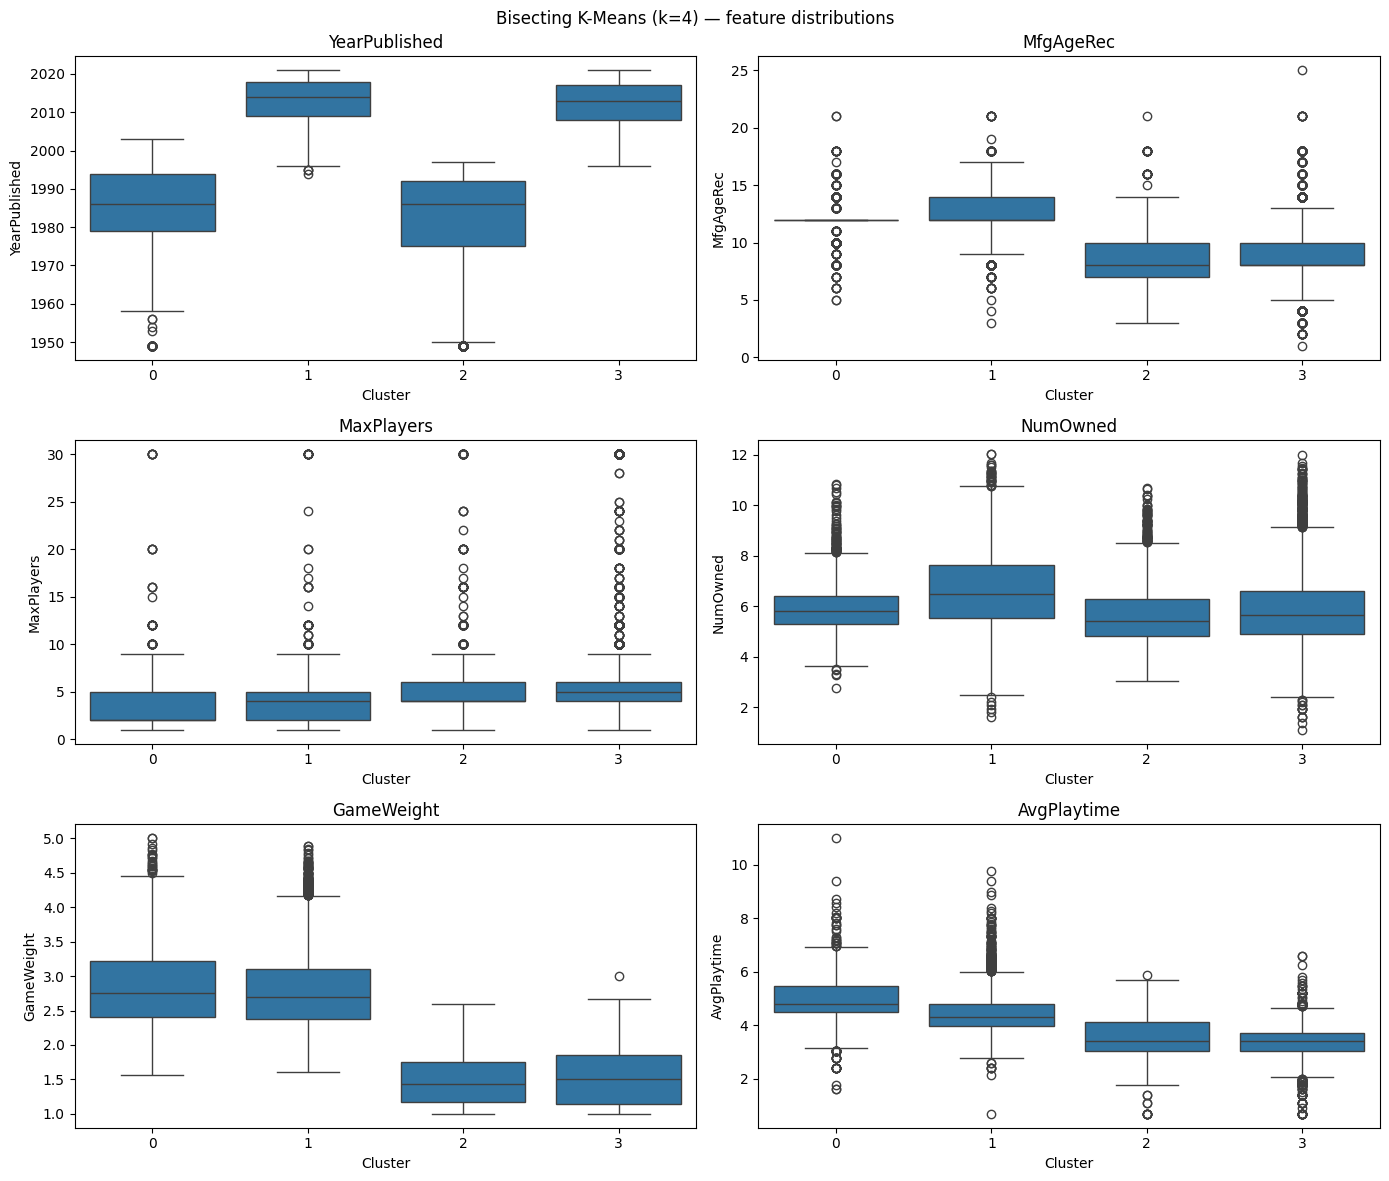

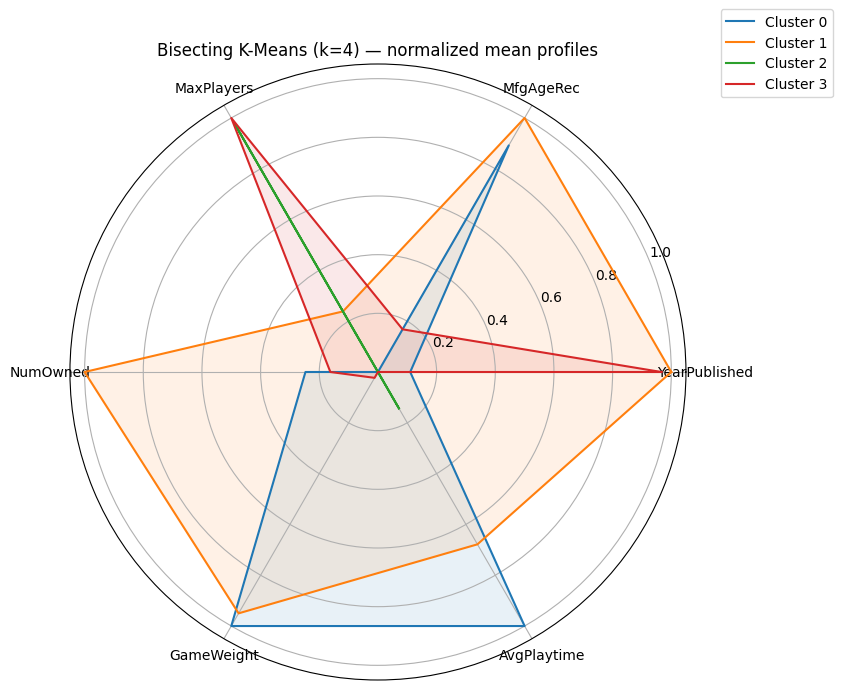

In [11]:
# Final selected centroid-based solution
bisect_k4 = BisectingKMeans(
    n_clusters=4,
    random_state=RANDOM_STATE,
    n_init=10,
    bisecting_strategy="biggest_inertia",
)
labels_bk4 = bisect_k4.fit_predict(X_scaled)

print("Bisecting K-Means k=4:", partition_summary(X_scaled, labels_bk4))
display(cluster_profiles(X, labels_bk4))
display(feature_effect_sizes(X, labels_bk4))

plot_pca_partition(X_scaled, labels_bk4, "Bisecting K-Means (k=4) — PCA projection")
plot_boxplots(X, labels_bk4, title="Bisecting K-Means (k=4) — feature distributions")
plot_spider_profiles(X, labels_bk4, title="Bisecting K-Means (k=4) — normalized mean profiles")

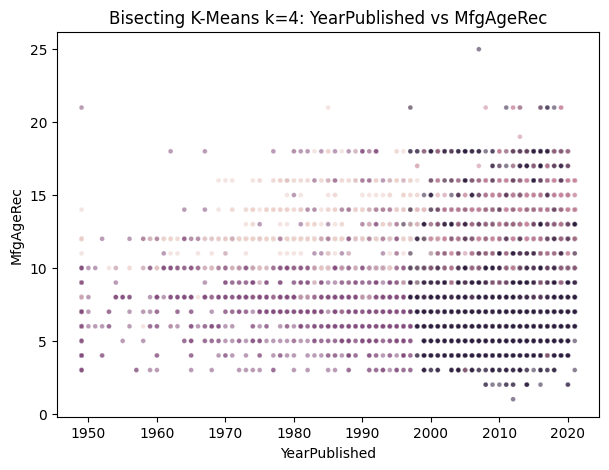

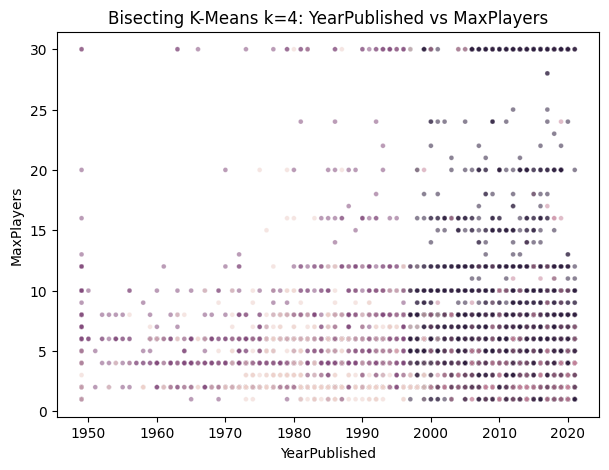

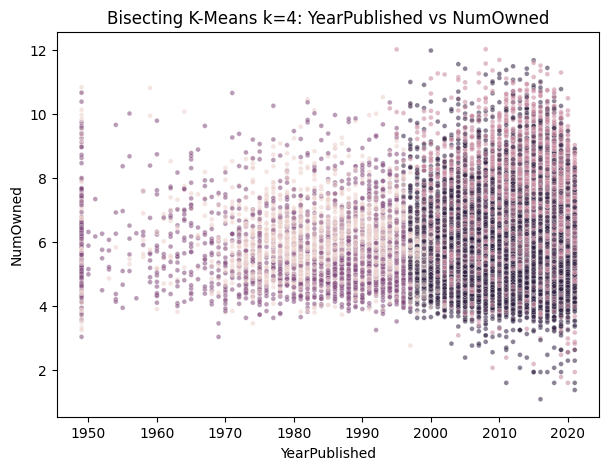

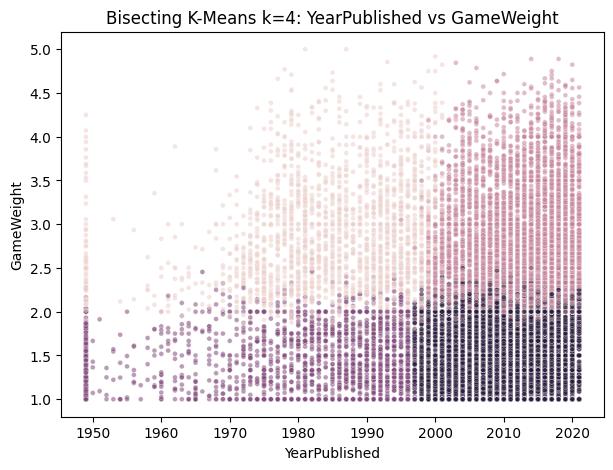

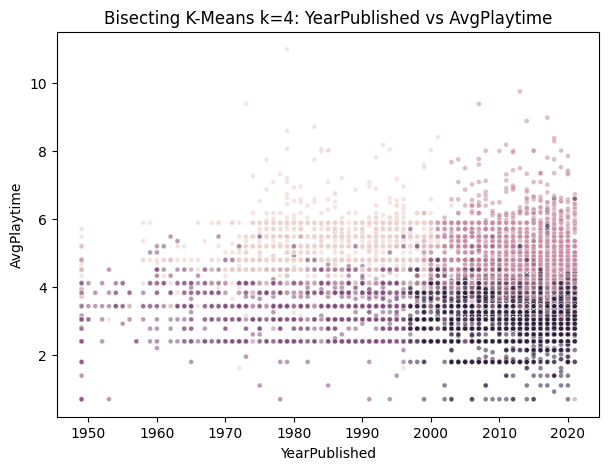

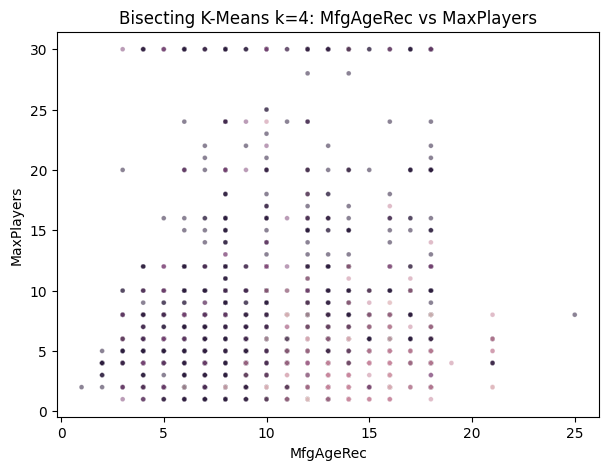

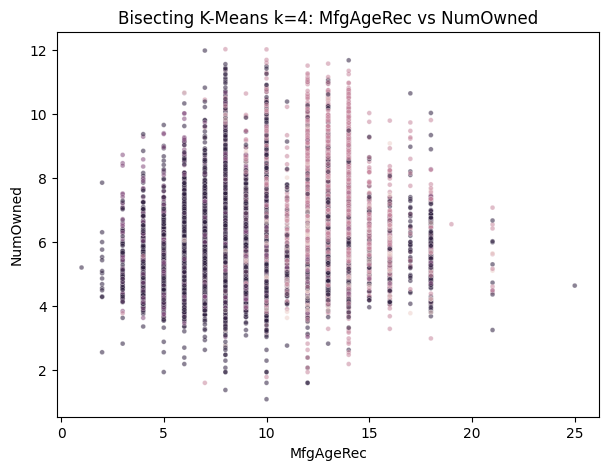

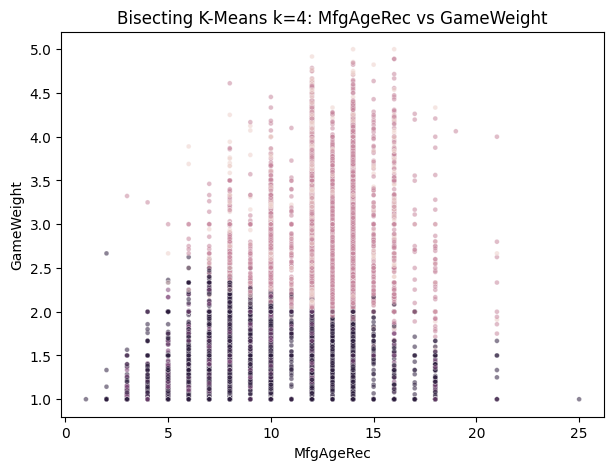

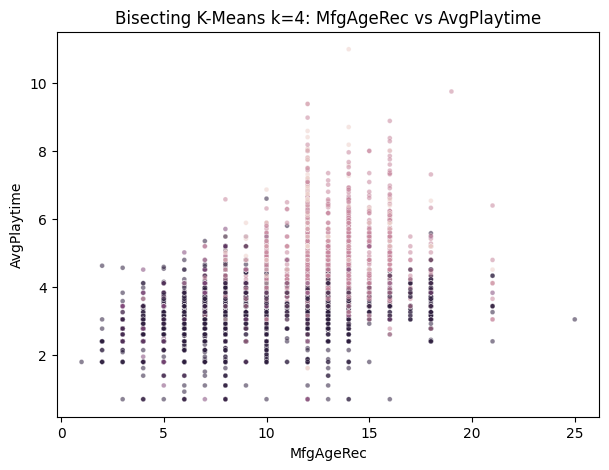

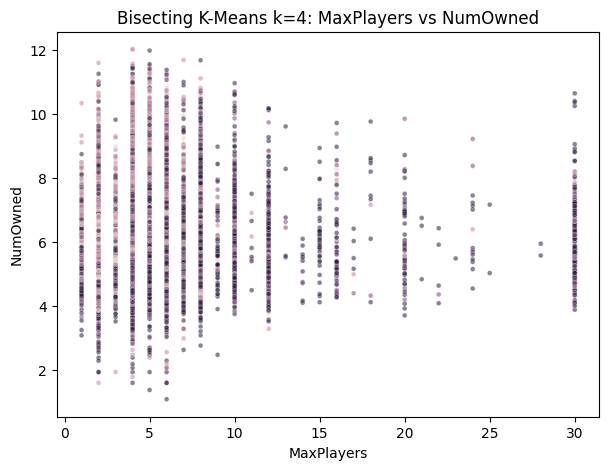

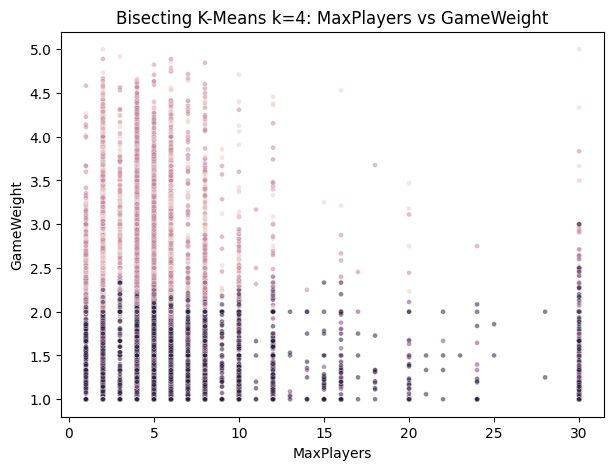

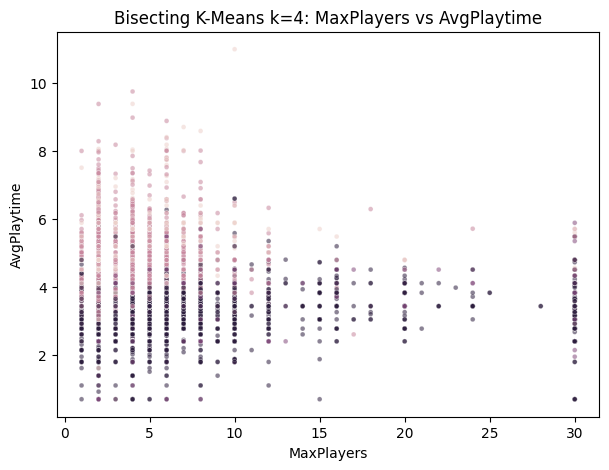

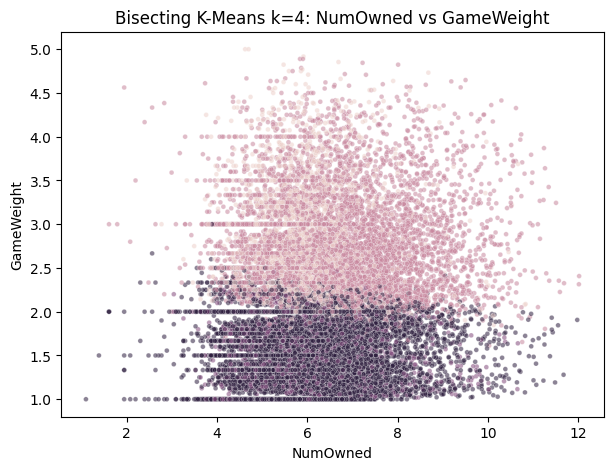

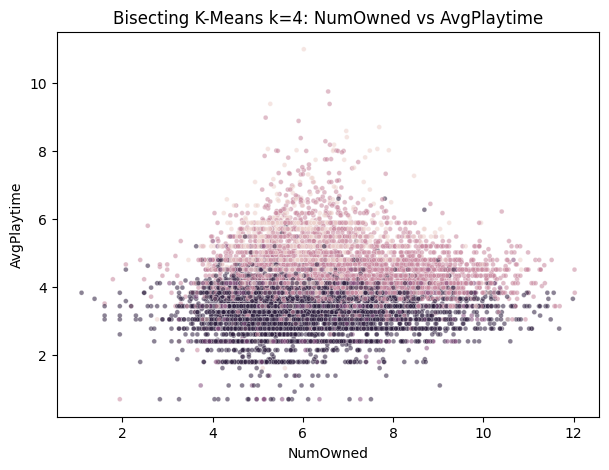

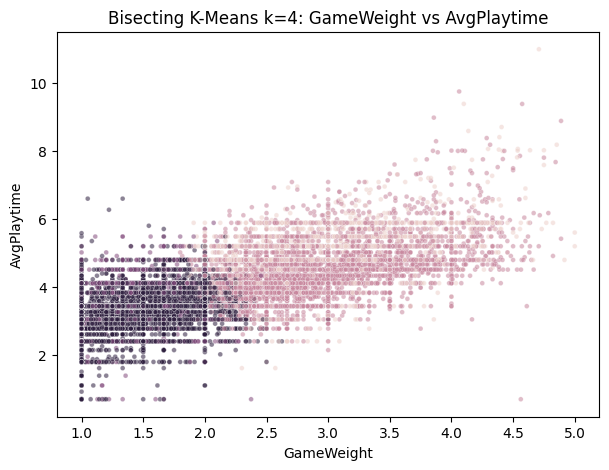

In [12]:
# All 2D projections used in the project to inspect cluster boundaries: change to True to run (we temporarily disabled it to save time)
RUN_PAIRWISE_PROJECTIONS = True

if RUN_PAIRWISE_PROJECTIONS:
    temp = X.copy()
    temp["Cluster"] = labels_bk4
    pairs = list(combinations(CLUSTER_FEATURES, 2))
    for x_col, y_col in pairs:
        plt.figure(figsize=(7, 5))
        sns.scatterplot(data=temp, x=x_col, y=y_col, hue="Cluster", s=12, alpha=0.55, legend=False)
        plt.title(f"Bisecting K-Means k=4: {x_col} vs {y_col}")
        plt.show()

## 3.2 Analysis by Density-Based Methods

### 3.2.1 Parameter selection and application

We first evaluated DBSCAN using the common heuristics `d+1`, `2d` and `log(n)` for `min_samples`, with `eps` estimated from the k-distance curve. A broader DBSCAN grid search follows. OPTICS and HDBSCAN are then used as additional checks because DBSCAN repeatedly produced a dominant cluster, noise and/or micro-clusters.

The broad searches are expensive, therefore in the notebook we kept them disabled by default.

In [13]:
def knee_point_from_chord(sorted_values):
    y = np.asarray(sorted_values, dtype=float)
    n = len(y)
    if n < 3:
        return int(np.argmax(y))
    x = np.arange(n, dtype=float)
    p1 = np.array([x[0], y[0]])
    p2 = np.array([x[-1], y[-1]])
    line = p2 - p1
    denom = np.linalg.norm(line)
    if denom == 0:
        return int(np.argmax(y))
    points = np.column_stack([x, y])
    distances = np.abs(np.cross(line, points - p1) / denom)
    return int(np.argmax(distances))


def evaluate_density_labels(Xs, labels, metric="euclidean"):
    labels = np.asarray(labels)
    non_noise = labels != -1
    unique = np.unique(labels[non_noise])
    sil = np.nan
    if len(unique) >= 2 and non_noise.sum() > len(unique):
        sil = float(silhouette_score(Xs[non_noise], labels[non_noise], metric=metric))
    sizes = pd.Series(labels[non_noise]).value_counts()
    return {
        "n_clusters": len(unique),
        "silhouette": sil,
        "noise_ratio": float((labels == -1).mean()),
        "dominant_share_non_noise": float(sizes.max() / sizes.sum()) if len(sizes) else np.nan,
        "cv": cluster_size_cv(labels, ignore_noise=True),
    }

In [14]:
# Initial DBSCAN heuristic experiment recovered from the supplied density notebook.
d = X_scaled.shape[1]
n = X_scaled.shape[0]
heuristic_min_samples = sorted(set([d + 1, 2 * d, int(round(np.log(n))) ]))

heuristic_rows = []
for metric in ["euclidean", "manhattan"]:
    for min_samples in heuristic_min_samples:
        nn = NearestNeighbors(n_neighbors=min_samples + 1, metric=metric).fit(X_scaled)
        distances, _ = nn.kneighbors(X_scaled)
        k_dist = np.sort(distances[:, min_samples])
        knee_idx = knee_point_from_chord(k_dist)
        eps = float(k_dist[knee_idx])

        labels = DBSCAN(eps=eps, min_samples=min_samples, metric=metric).fit_predict(X_scaled)
        rec = {"metric": metric, "min_samples": min_samples, "eps": eps}
        rec.update(evaluate_density_labels(X_scaled, labels, metric=metric))
        heuristic_rows.append(rec)

heuristic_dbscan_results = pd.DataFrame(heuristic_rows)
display(heuristic_dbscan_results)

,metric,min_samples,eps,n_clusters,silhouette,noise_ratio,dominant_share_non_noise,cv
0,euclidean,7,0.130149,5,0.315740,0.030236,0.993016,1.982567
1,euclidean,10,0.149168,3,0.406638,0.020173,0.993187,1.399774
2,euclidean,12,0.153817,3,0.406037,0.019641,0.993042,1.399469
3,manhattan,7,0.252999,2,0.464763,0.019206,0.992799,0.985597
4,manhattan,10,0.261760,2,0.464652,0.021141,0.993229,0.986458
5,manhattan,12,0.281006,2,0.464425,0.016690,0.992866,0.985733


In [15]:
# We specified min_samples over 30 values in [2, 200] and eps over [0.01, 2]
# with variable step sizes. The grid below follows those stated bounds.
RUN_DBSCAN_GRID = False

if RUN_DBSCAN_GRID:
    min_samples_grid = np.unique(np.round(np.geomspace(2, 200, 30)).astype(int))
    eps_grid = np.unique(np.concatenate([
        np.arange(0.01, 0.21, 0.01),
        np.arange(0.25, 1.01, 0.05),
        np.arange(1.10, 2.01, 0.10),
    ]))

    rows = []
    for metric in ["euclidean", "manhattan"]:
        for min_samples in min_samples_grid:
            for eps in eps_grid:
                labels = DBSCAN(eps=float(eps), min_samples=int(min_samples), metric=metric).fit_predict(X_scaled)
                rec = {"algorithm": "DBSCAN", "metric": metric, "min_samples": int(min_samples), "eps": float(eps)}
                rec.update(evaluate_density_labels(X_scaled, labels, metric=metric))
                rows.append(rec)

    dbscan_grid_results = pd.DataFrame(rows)
    display(dbscan_grid_results.head())

In [16]:
# OPTICS was evaluated on a random sample of 5,000 observations.
RUN_OPTICS_GRID = False

if RUN_OPTICS_GRID:
    rng = np.random.default_rng(RANDOM_STATE)
    sample_size = min(5000, len(X_scaled))
    sample_idx = rng.choice(len(X_scaled), size=sample_size, replace=False)
    X_optics = X_scaled[sample_idx]

    rows = []
    for min_samples in [5, 10, 20, 50]:
        for min_cluster_size in [20, 50, 100, 200]:
            for xi in np.linspace(0.005, 0.05, 8):
                model = OPTICS(
                    min_samples=min_samples,
                    min_cluster_size=min_cluster_size,
                    xi=float(xi),
                    metric="euclidean",
                    cluster_method="xi",
                )
                labels = model.fit_predict(X_optics)
                rec = {
                    "algorithm": "OPTICS",
                    "min_samples": min_samples,
                    "min_cluster_size": min_cluster_size,
                    "xi": float(xi),
                }
                rec.update(evaluate_density_labels(X_optics, labels, metric="euclidean"))
                rows.append(rec)

    optics_grid_results = pd.DataFrame(rows)
    display(optics_grid_results.head())

In [17]:
# Requires the optional `hdbscan` package.
RUN_HDBSCAN_GRID = False

if RUN_HDBSCAN_GRID:
    import hdbscan

    min_samples_grid = [None] + list(np.unique(np.round(np.geomspace(2, 200, 20)).astype(int)))
    min_cluster_size_grid = list(np.unique(np.round(np.geomspace(5, 1500, 30)).astype(int)))

    rows = []
    for metric in ["euclidean", "manhattan"]:
        for method in ["eom", "leaf"]:
            for min_samples in min_samples_grid:
                for min_cluster_size in min_cluster_size_grid:
                    model = hdbscan.HDBSCAN(
                        min_samples=min_samples,
                        min_cluster_size=int(min_cluster_size),
                        metric=metric,
                        cluster_selection_method=method,
                    )
                    labels = model.fit_predict(X_scaled)
                    rec = {
                        "algorithm": "HDBSCAN",
                        "metric": metric,
                        "cluster_selection_method": method,
                        "min_samples": min_samples,
                        "min_cluster_size": int(min_cluster_size),
                    }
                    rec.update(evaluate_density_labels(X_scaled, labels, metric=metric))
                    rows.append(rec)

    hdbscan_grid_results = pd.DataFrame(rows)
    display(hdbscan_grid_results.head())

In [18]:
def plot_density_tradeoff(results, title):
    valid = results[(results["n_clusters"] > 1)].copy()
    if valid.empty:
        print("No multi-cluster configurations to plot.")
        return
    plt.figure(figsize=(8, 5))
    plt.scatter(valid["noise_ratio"], valid["dominant_share_non_noise"], s=18, alpha=0.65)
    plt.xlabel("Noise fraction")
    plt.ylabel("Largest cluster share (non-noise points)")
    plt.title(title)
    plt.show()

# Examples after running the expensive grids:
# plot_density_tradeoff(dbscan_grid_results, "DBSCAN trade-off")
# plot_density_tradeoff(optics_grid_results, "OPTICS trade-off")
# plot_density_tradeoff(hdbscan_grid_results, "HDBSCAN trade-off")

### 3.2.2 Results

 DBSCAN, OPTICS and HDBSCAN do **not** produce a useful segmentation of this dataset. Across the tested configurations, solutions are dominated by a single large cluster with varying amounts of noise or by small micro-clusters. The key diagnostic is the trade-off between **noise fraction** and the **largest non-noise cluster share**: no tested configuration simultaneously produces several meaningful clusters, reasonable size balance and an acceptable noise level.

## 3.3 Analysis by Hierarchical Clustering

### 3.3.1 Parameter selection and application

We compared::

- Ward + Euclidean;
- complete linkage + Euclidean/Manhattan;
- average linkage + Euclidean/Manhattan;
- single linkage + Euclidean/Manhattan.

Ward is only paired with Euclidean distance. The evaluation uses dendrogram structure, cophenetic correlation coefficient (CCC), silhouette score, SSE for Euclidean configurations, cluster-size range and CV. The largest merge gaps are used to identify plausible dendrogram cuts.

The original full-data hierarchical experiments are computationally expensive. The cells below reproduce the method but keep the full grid disabled by default.

In [19]:
def within_cluster_sse(Xs, labels):
    total = 0.0
    for cluster_id in np.unique(labels):
        pts = Xs[labels == cluster_id]
        centroid = pts.mean(axis=0)
        total += ((pts - centroid) ** 2).sum()
    return float(total)


RUN_HIERARCHICAL_GRID = True

if RUN_HIERARCHICAL_GRID:
    rows = []
    configurations = [
        ("ward", "euclidean"),
        ("complete", "euclidean"), ("complete", "manhattan"),
        ("average", "euclidean"), ("average", "manhattan"),
        ("single", "euclidean"), ("single", "manhattan"),
    ]

    for linkage, metric in configurations:
        for k in range(2, 11):
            model = AgglomerativeClustering(n_clusters=k, linkage=linkage, metric=metric)
            labels = model.fit_predict(X_scaled)
            sizes = pd.Series(labels).value_counts()
            rows.append({
                "linkage": linkage,
                "metric": metric,
                "k": k,
                "silhouette": silhouette_score(X_scaled, labels, metric=metric),
                "sse": within_cluster_sse(X_scaled, labels) if metric == "euclidean" else np.nan,
                "min_cluster_size": int(sizes.min()),
                "max_cluster_size": int(sizes.max()),
                "cv": float(sizes.std(ddof=0) / sizes.mean()),
            })

    hierarchical_grid_results = pd.DataFrame(rows)
    display(hierarchical_grid_results)

,linkage,metric,k,silhouette,sse,min_cluster_size,max_cluster_size,cv
0,ward,euclidean,2,0.194032,2131.673202,8182,12489,0.208360
1,ward,euclidean,3,0.204173,1724.826422,3225,9264,0.381571
2,ward,euclidean,4,0.195374,1548.931417,881,9264,0.699142
3,ward,euclidean,5,0.204955,1382.355534,385,9264,0.889239
4,ward,euclidean,6,0.161926,1256.399074,385,7797,0.746025
...,...,...,...,...,...,...,...,...
58,single,manhattan,6,0.401336,NaN,1,20665,2.235289
59,single,manhattan,7,0.383205,NaN,1,20664,2.448522
60,single,manhattan,8,0.377690,NaN,1,20663,2.644581
61,single,manhattan,9,0.377649,NaN,1,20662,2.827042


,linkage,metric,CCC
3,average,euclidean,0.727207
4,average,cityblock,0.665216
1,complete,euclidean,0.634562
5,single,euclidean,0.565456
2,complete,cityblock,0.540024
6,single,cityblock,0.501651
0,ward,euclidean,0.443785


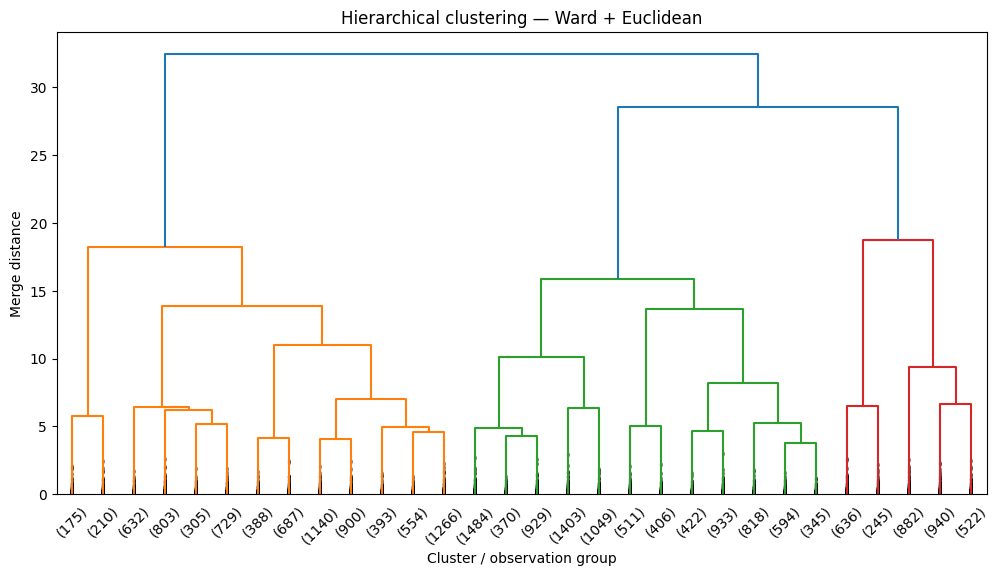

In [20]:
# Full linkage matrices and CCC, are implemented
# but are memory-intensive on ~20k rows because pairwise distances scale as O(n^2).
RUN_FULL_LINKAGE_AND_CCC = True

if RUN_FULL_LINKAGE_AND_CCC:
    from scipy.cluster.hierarchy import linkage, dendrogram
    from scipy.spatial.distance import pdist
    from scipy.cluster.hierarchy import cophenet

    configurations = [
        ("ward", "euclidean"),
        ("complete", "euclidean"), ("complete", "cityblock"),
        ("average", "euclidean"), ("average", "cityblock"),
        ("single", "euclidean"), ("single", "cityblock"),
    ]

    ccc_rows = []
    linkage_matrices = {}
    for method, metric in configurations:
        if method == "ward":
            Z = linkage(X_scaled, method="ward", metric="euclidean")
            distances = pdist(X_scaled, metric="euclidean")
        else:
            distances = pdist(X_scaled, metric=metric)
            Z = linkage(distances, method=method)

        ccc, _ = cophenet(Z, distances)
        linkage_matrices[(method, metric)] = Z
        ccc_rows.append({"linkage": method, "metric": metric, "CCC": ccc})

    ccc_results = pd.DataFrame(ccc_rows).sort_values("CCC", ascending=False)
    display(ccc_results)

    # Report figure: Ward + Euclidean dendrogram, truncated for readability.
    Z_ward = linkage_matrices[("ward", "euclidean")]
    plt.figure(figsize=(12, 6))
    dendrogram(Z_ward, truncate_mode="lastp", p=30, show_contracted=True)
    plt.title("Hierarchical clustering — Ward + Euclidean")
    plt.xlabel("Cluster / observation group")
    plt.ylabel("Merge distance")
    plt.show()

The reported CCC values are approximately:

- average + Euclidean: **0.64**
- average + Manhattan: **0.60**
- Ward + Euclidean: **0.49**

However, CCC alone is not used to choose the final partition because average and especially single linkage can yield degenerate mega-cluster/micro-cluster structures. Ward + Euclidean is retained as the most robust hierarchical configuration when interpretability and cluster-size balance are considered together.

,n_clusters,silhouette,cv,min_cluster_size,max_cluster_size,noise_ratio,dominant_share_non_noise,k
0,3,0.204173,0.381571,3225,9264,0.0,0.448164,3
1,4,0.195374,0.699142,881,9264,0.0,0.448164,4
2,5,0.204955,0.889239,385,9264,0.0,0.448164,5


,YearPublished,MfgAgeRec,MaxPlayers,NumOwned,GameWeight,AvgPlaytime,Count
Cluster,,,,,,,
0,2007.935835,9.018577,6.252383,5.761963,1.341170,3.295765,8182
1,1990.504266,12.031143,3.331058,5.844051,2.980819,5.003787,2344
2,2013.308830,11.267055,4.259067,6.445686,2.448392,4.067179,9264
3,1967.701476,8.192963,4.400681,5.864630,1.563174,3.480120,881


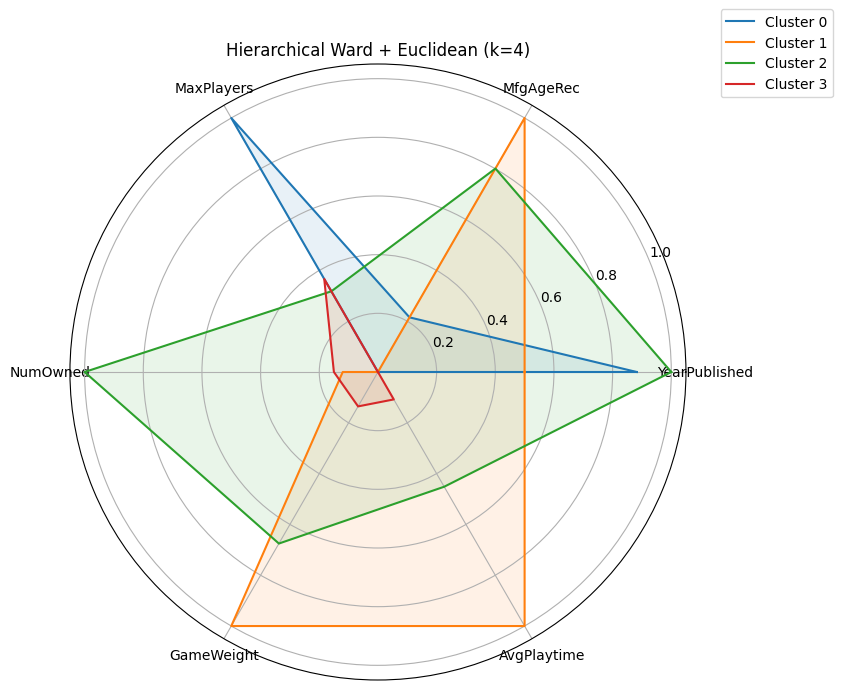

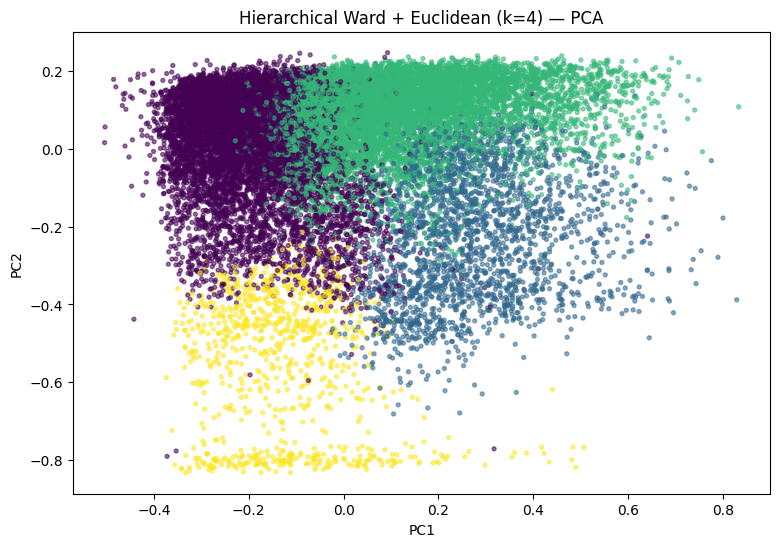

In [21]:
# Compare the Ward solutions
RUN_SELECTED_HIERARCHICAL = True

if RUN_SELECTED_HIERARCHICAL:
    ward_rows = []
    ward_labels = {}
    for k in [3, 4, 5]:
        model = AgglomerativeClustering(n_clusters=k, linkage="ward", metric="euclidean")
        labels = model.fit_predict(X_scaled)
        ward_labels[k] = labels
        summary = partition_summary(X_scaled, labels, ignore_noise=False)
        summary["k"] = k
        ward_rows.append(summary)

    display(pd.DataFrame(ward_rows))

    # Focuses especially on k=4.
    labels_h4 = ward_labels[4]
    display(cluster_profiles(X, labels_h4))
    plot_spider_profiles(X, labels_h4, title="Hierarchical Ward + Euclidean (k=4)")
    plot_pca_partition(X_scaled, labels_h4, title="Hierarchical Ward + Euclidean (k=4) — PCA")

### 3.3.2 Results

Ward + Euclidean silhouettes of approximately **0.2468 (k=3)**, **0.2315 (k=4)** and **0.1527 (k=5)**. The `k=3` and `k=4` partitions correspond closely to the centroid-based structure, although the hierarchical solutions are more sensitive to points close to cluster boundaries.

## 3.5 Final Discussion

The final comparison in the report can be summarized as follows:

- **Density-based methods** do not uncover a stable, balanced density structure in the selected numerical space; they tend to produce a dominant cluster plus noise or many micro-clusters.
- **Hierarchical Ward + Euclidean** identifies structures highly consistent with the centroid-based partitions, but is more sensitive to observations near boundaries.
- **Bisecting K-Means with k=4** provides the clearest structural segmentation used in the project interpretation: the main separation is driven by publication period and game complexity, while other variables refine the groups.
- **Semantic BERTopic clustering** adds thematic information that is not represented by the numerical features, allowing structurally similar games to be distinguished by content and theme.

Together, the numerical and semantic analyses provide complementary views of the board-game dataset.